## Wine Dataset Classifcation

### Model Archtictrue

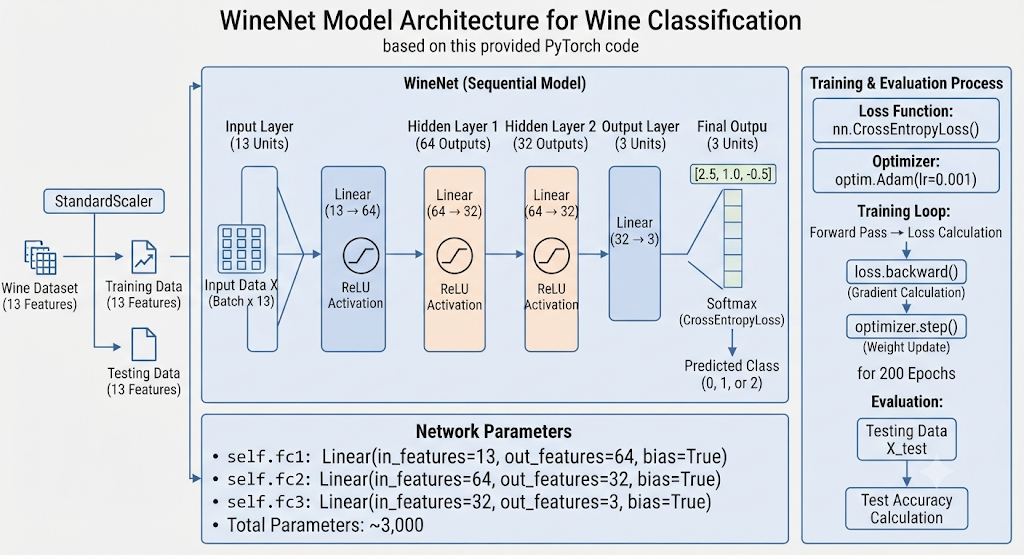

In [197]:
import torch
import torch.nn as nn
import torch.optim as optim

import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split

from sklearn.preprocessing import StandardScaler


In [198]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


### Load Wine Dataset

In [199]:
wine = load_wine()
X = wine.data
y = wine.target
print(X.shape, y.shape)

(178, 13) (178,)


In [200]:
## Winde Dataset Fatures
print(wine.feature_names)

['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']


In [201]:
## Winde Dataset Class
print(wine.target_names)

['class_0' 'class_1' 'class_2']


### Scalling X dataset and Splitting Train and test set

In [202]:
# Feature Scaling
scaler = StandardScaler()
X = scaler.fit_transform(X)

In [203]:
# Train Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

### Train and test Data Converting In Tensor format

In [204]:
# Convert Tensor
X_train = torch.tensor(X_train, dtype=torch.float32).to(device)
X_test = torch.tensor(X_test, dtype=torch.float32).to(device)

y_train = torch.tensor(y_train, dtype=torch.long).to(device)
y_test = torch.tensor(y_test, dtype=torch.long).to(device)


### Neural Netwok Mode Define

In [205]:
# Neural Network Model
class WineNet(nn.Module):

    def __init__(self):
        super().__init__()

        self.fc1 = nn.Linear(13, 64)
        self.fc2 = nn.Linear(64, 32)
        self.fc3 = nn.Linear(32, 3)

        self.relu = nn.ReLU()

    def forward(self, x):

        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.fc3(x)

        return x

model = WineNet().to(device)
model

WineNet(
  (fc1): Linear(in_features=13, out_features=64, bias=True)
  (fc2): Linear(in_features=64, out_features=32, bias=True)
  (fc3): Linear(in_features=32, out_features=3, bias=True)
  (relu): ReLU()
)

In [206]:
# Loss Function
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)


In [207]:
# Training & Metric Tracking
epochs = 300
train_losses, train_accuracies = [], []
test_losses, test_accuracies = [], []

for epoch in range(epochs):
  # Training
  model.train()
  optimizer.zero_grad()
  outputs = model(X_train)
  loss = criterion(outputs, y_train)
  loss.backward()
  optimizer.step()

  _, predicted = torch.max(outputs, 1)
  train_acc = (predicted == y_train).float().mean() * 100

  train_losses.append(loss.item())
  train_accuracies.append(train_acc.item())

  # Evaluation / Testing
  model.eval()
  with torch.no_grad():
    test_outputs = model(X_test)
    test_loss = criterion(test_outputs, y_test)
    _, test_predicted = torch.max(test_outputs, 1)
    test_acc = (test_predicted == y_test).float().mean() * 100

    test_losses.append(test_loss.item())
    test_accuracies.append(test_acc.item())

  if (epoch + 1) % 20 == 0:
    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Train Loss: {loss.item():.4f} | Train Acc: {train_acc:.2f}% "
        f"| Test Loss: {test_loss.item():.4f} | Test Acc: {test_acc:.2f}%"
    )

Epoch [20/300] Train Loss: 0.7882 | Train Acc: 95.77% | Test Loss: 0.7541 | Test Acc: 91.67%
Epoch [40/300] Train Loss: 0.4240 | Train Acc: 97.18% | Test Loss: 0.3980 | Test Acc: 94.44%
Epoch [60/300] Train Loss: 0.1751 | Train Acc: 98.59% | Test Loss: 0.1887 | Test Acc: 94.44%
Epoch [80/300] Train Loss: 0.0774 | Train Acc: 98.59% | Test Loss: 0.1248 | Test Acc: 91.67%
Epoch [100/300] Train Loss: 0.0401 | Train Acc: 100.00% | Test Loss: 0.1096 | Test Acc: 94.44%
Epoch [120/300] Train Loss: 0.0236 | Train Acc: 100.00% | Test Loss: 0.1051 | Test Acc: 94.44%
Epoch [140/300] Train Loss: 0.0153 | Train Acc: 100.00% | Test Loss: 0.1049 | Test Acc: 94.44%
Epoch [160/300] Train Loss: 0.0108 | Train Acc: 100.00% | Test Loss: 0.1049 | Test Acc: 94.44%
Epoch [180/300] Train Loss: 0.0080 | Train Acc: 100.00% | Test Loss: 0.1054 | Test Acc: 94.44%
Epoch [200/300] Train Loss: 0.0062 | Train Acc: 100.00% | Test Loss: 0.1065 | Test Acc: 94.44%
Epoch [220/300] Train Loss: 0.0050 | Train Acc: 100.00% | 

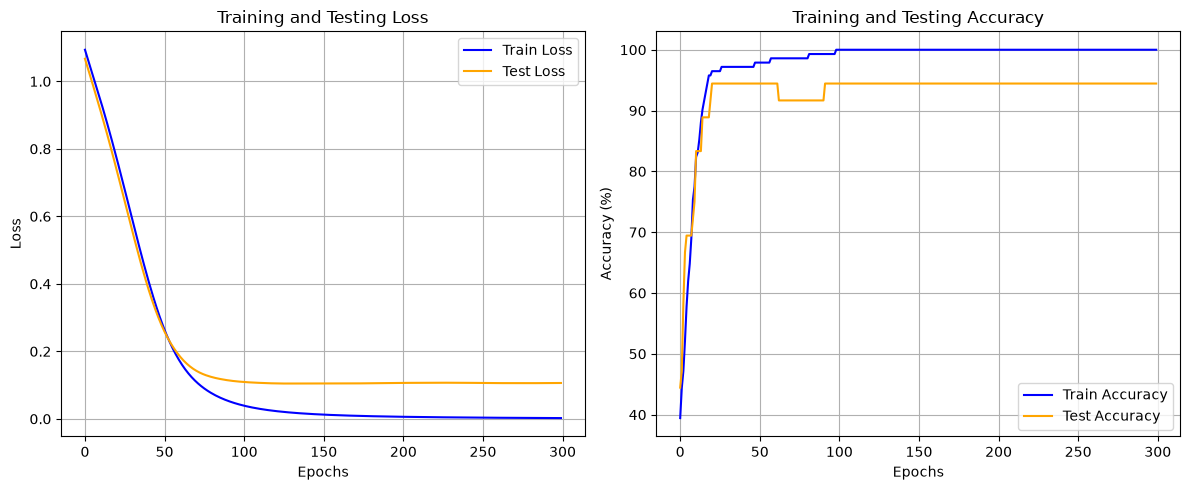

In [208]:
# ------------------------------------------------
# Plotting Loss and Accuracy Curves
# ------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Loss Subplot
ax1.plot(train_losses, label="Train Loss", color="blue")
ax1.plot(test_losses, label="Test Loss", color="orange")
ax1.set_title("Training and Testing Loss")
ax1.set_xlabel("Epochs")
ax1.set_ylabel("Loss")
ax1.legend()
ax1.grid(True)

# Accuracy Subplot
ax2.plot(train_accuracies, label="Train Accuracy", color="blue")
ax2.plot(test_accuracies, label="Test Accuracy", color="orange")
ax2.set_title("Training and Testing Accuracy")
ax2.set_xlabel("Epochs")
ax2.set_ylabel("Accuracy (%)")
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

In [209]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

In [210]:
# Convert CUDA tensors to CPU NumPy
y_true = y_test.cpu().numpy()
y_pred = test_predicted.cpu().numpy()

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
print("Confusion Matrix:")
print(cm)


Confusion Matrix:
[[12  0  0]
 [ 1 13  0]
 [ 0  1  9]]


### Classification Report

In [211]:
# Classification Report
print("\nClassification Report:\n")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=wine.target_names
    )
)


Classification Report:

              precision    recall  f1-score   support

     class_0       0.92      1.00      0.96        12
     class_1       0.93      0.93      0.93        14
     class_2       1.00      0.90      0.95        10

    accuracy                           0.94        36
   macro avg       0.95      0.94      0.95        36
weighted avg       0.95      0.94      0.94        36



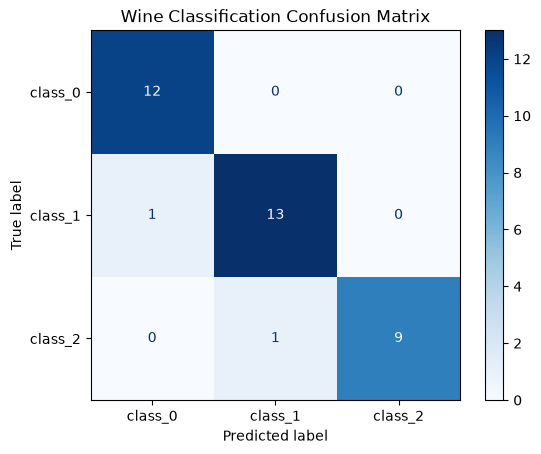

In [212]:
# Plot Confusion Matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=wine.target_names
)
disp.plot(
    cmap="Blues",
    values_format="d"
)
plt.title("Wine Classification Confusion Matrix")
plt.show()

In [213]:
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_true, y_pred)
print(f"Model Accuracy: {accuracy*100:.2f}%")

Model Accuracy: 94.44%


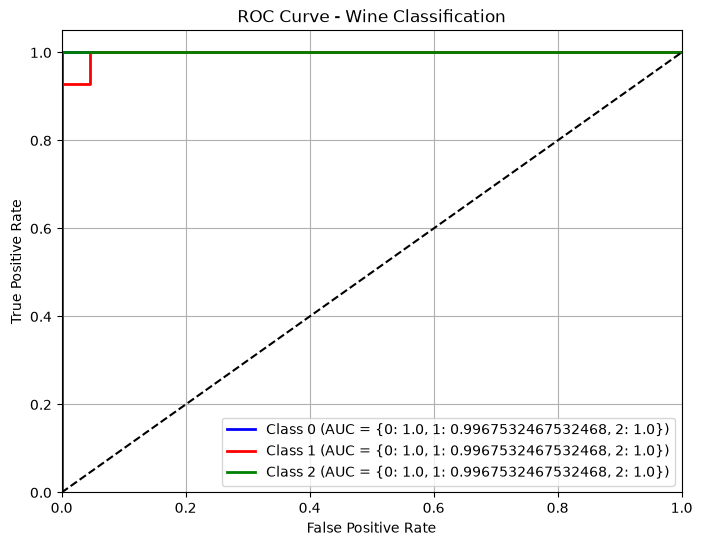


AUC Scores
Class 0: {0: 1.0, 1: 0.9967532467532468, 2: 1.0}
Class 1: {0: 1.0, 1: 0.9967532467532468, 2: 1.0}
Class 2: {0: 1.0, 1: 0.9967532467532468, 2: 1.0}


In [214]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
import numpy as np

# ---------------------------------
# Get Class Probabilities
# ---------------------------------
model.eval()
with torch.no_grad():
    outputs = model(X_test)
    # Softmax probabilities
    probabilities = torch.softmax(outputs, dim=1)

# Convert to numpy
y_score = probabilities.cpu().numpy()
y_true = y_test.cpu().numpy()

# ---------------------------------
# One-Hot Encode Labels
# ---------------------------------
n_classes = 3
y_true_bin = label_binarize(
    y_true,
    classes=[0, 1, 2]
)

# ---------------------------------
# ROC and AUC
# ---------------------------------
fpr = {}
tpr = {}
roc_auc = {}

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(
        y_true_bin[:, i],
        y_score[:, i]
    )
    roc_auc[i] = auc(
        fpr[i],
        tpr[i]
    )
    
# ---------------------------------
# Plot ROC Curves
# ---------------------------------
plt.figure(figsize=(8, 6))
colors = ["blue", "red", "green"]

for i, color in zip(range(n_classes), colors):
    plt.plot(
        fpr[i],
        tpr[i],
        color=color,
        lw=2,
        label=f"Class {i} (AUC = {roc_auc})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    color="black",
    linestyle="--"
)

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Wine Classification")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

# ---------------------------------
# Print AUC Scores
# ---------------------------------
print("\nAUC Scores")
for i in range(n_classes):
    print(
        f"Class {i}: {roc_auc}"
    )

In [215]:
from sklearn.metrics import roc_auc_score

macro_auc = roc_auc_score(
    y_true_bin,
    y_score,
    multi_class="ovr",
    average="macro"
)

weighted_auc = roc_auc_score(
    y_true_bin,
    y_score,
    multi_class="ovr",
    average="weighted"
)

print(f"\nMacro AUC    : {macro_auc:.4f}")
print(f"Weighted AUC : {weighted_auc:.4f}")


Macro AUC    : 0.9989
Weighted AUC : 0.9987


### Save Model

In [216]:
import torch
torch.save(
    model.state_dict(),
    "wine_model.pth"
)
print("Model Saved")

Model Saved


### load Model

In [217]:
model.load_state_dict(
    torch.load(
        "wine_model.pth",
        map_location=device
    )
)
model.eval()
print("Model Loaded")

Model Loaded


## Model  Inference

In [218]:
new_wine = [[
    13.2,   # alcohol
    1.78,   # malic acid
    2.14,   # ash
    11.2,   # alcalinity of ash
    100,    # magnesium
    2.65,   # total phenols
    2.76,   # flavanoids
    0.26,   # nonflavanoid phenols
    1.28,   # proanthocyanins
    4.38,   # color intensity
    1.05,   # hue
    3.40,   # OD280/OD315
    1050    # proline
]]

In [219]:
# Scaling it New data
new_wine_scaled = scaler.transform(
    new_wine
)
new_wine_scaled

array([[ 0.24628963, -0.49941338, -0.82799632, -2.49084714,  0.01814502,
         0.56864766,  0.73362894, -0.82071924, -0.54472099, -0.29332133,
         0.40605066,  1.1134493 ,  0.96524152]])

In [220]:
# Convert to tensor
input_tensor = torch.tensor(
    new_wine_scaled,
    dtype=torch.float32
).to(device)

input_tensor

tensor([[ 0.2463, -0.4994, -0.8280, -2.4908,  0.0181,  0.5686,  0.7336, -0.8207,
         -0.5447, -0.2933,  0.4061,  1.1134,  0.9652]], device='cuda:0')

### Predic New Data

In [221]:
with torch.no_grad():
    outputs_new = model(input_tensor)
    _, prediction_new = torch.max(
        outputs_new,
        dim=1
    )

print(
    "Predicted Class:",
    prediction_new.item()
)

Predicted Class: 0


#### Get Prediction Probability

In [222]:
with torch.no_grad():
    outputs_new = model(input_tensor)
    probabilities = torch.softmax(
        outputs_new,
        dim=1
    )
    
print(probabilities)


tensor([[9.9974e-01, 1.7339e-04, 8.5605e-05]], device='cuda:0')


### Human Readable Prediction

In [223]:
class_names = [
    "Cultivar 1",
    "Cultivar 2",
    "Cultivar 3"
]

predicted_class = prediction_new.item()

print(
    "Wine Type:",
    class_names[predicted_class]
)

Wine Type: Cultivar 1


### Better Production Saving (Recommended)

In [224]:
# Save Model with Information
checkpoint = {
    "model_state_dict": model.state_dict(),
    "input_size": 13,
    "hidden1": 64,
    "hidden2": 32,
    "num_classes": 3
}

torch.save(
    checkpoint,
    "wine_checkpoint.pth"
)

In [225]:
## Load Model
checkpoint = torch.load(
    "wine_checkpoint.pth",
    map_location=device
)
model = WineNet().to(device)
model.load_state_dict(
    checkpoint["model_state_dict"]
)
model.eval()

WineNet(
  (fc1): Linear(in_features=13, out_features=64, bias=True)
  (fc2): Linear(in_features=64, out_features=32, bias=True)
  (fc3): Linear(in_features=32, out_features=3, bias=True)
  (relu): ReLU()
)